In [1]:
import numpy as np
from sentence_transformers import SentenceTransformer


sentences = [
    "Eu ainda acho que isso é uma péssima ideia",
    "Aquele corredor não devia estar aberto",
    "Tem alguma coisa errada ali",
    "Você também sentiu isso?",
    "Parece que estamos sendo observados",
    "Talvez seja só impressão",
    "Mesmo assim, melhor não arriscar",
    "A gente devia voltar",
    "Mas agora já estamos aqui",
    "Só vamos dar uma olhada rápida",
    "Promete que é só uma olhada?",
    "Prometo",
    "Então vamos logo",
    "Essa escola guarda muitos segredos",
    "Principalmente nos lugares proibidos",
    "E geralmente tem um motivo pra serem proibidos",
    "Você acha que alguém está escondendo algo?",
    "Não duvido",
    "Hogwarts sempre teve mistérios",
    "E a gente sempre acaba se metendo neles",
    
    "Talvez tudo isso seja como resolver um problema complicado",
    "Você quer dizer tipo um enigma?",
    "Sim, como seguir pistas até chegar na solução",
    "É como montar um quebra-cabeça",
    "Ou como encontrar uma resposta passo a passo",
    "Isso parece até lógica de programação",
    "Programação?",
    "Sim, resolver problemas com código",
    "Tipo dar instruções para algo funcionar",
    "Nunca pensei nisso assim",
    
    "Na programação tudo precisa fazer sentido",
    "Cada passo depende do anterior",
    "Se algo dá errado, você precisa investigar",
    "E corrigir o erro",
    "Isso parece até o que estamos fazendo aqui",
    "Só que com menos risco de morrer",
    "Depende do código",
    "Já vi código quebrar tudo",
    "Que tipo de código?",
    "Python, por exemplo",
    
    "Eu já ouvi falar disso",
    "É uma linguagem de programação",
    "Usada para várias coisas",
    "Como inteligência artificial",
    "Análise de dados",
    "E até jogos",
    "Interessante",
    "Talvez seja menos perigoso que esse corredor",
    "Com certeza é",
    "Mas também pode ser frustrante",
    "Então ainda parece um pouco com isso aqui",
    "Só que sem criaturas assustadoras",
    "Na maioria das vezes"
]

sentences_e5 = [f"passage: {s}" for s in sentences]
model = SentenceTransformer('intfloat/multilingual-e5-base')

S = model.encode(sentences_e5)

print("\nEmbeddings (S):")
print(S.shape)
print(S)

c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17153.03it/s]
XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-base
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embeddings (S):
(53, 768)
[[-0.01059809  0.03678444 -0.02576696 ... -0.04533979 -0.02788713
  -0.0010166 ]
 [ 0.00600717  0.01689684 -0.03228225 ... -0.05023766 -0.0434422
   0.03852928]
 [-0.00040902  0.00715171 -0.03099365 ... -0.050642   -0.04966634
   0.03481925]
 ...
 [-0.00100207  0.01709163 -0.03238844 ... -0.04189399 -0.03671903
   0.03248368]
 [ 0.0157796   0.01378352 -0.03542505 ... -0.04946708 -0.03165706
   0.04055379]
 [ 0.02989168  0.02478207 -0.03221355 ... -0.03670211 -0.02714149
   0.03366282]]


In [2]:
S = model.encode(sentences_e5, normalize_embeddings=False)

scores = np.dot(S, S.T)

n = len(sentences)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i:
            A[i, j] = scores[i, j]

print(A)

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.88360041 0.         0.         ... 0.         0.         0.        ]
 [0.86499417 0.86492842 0.         ... 0.         0.         0.        ]
 ...
 [0.91266847 0.86669707 0.8743993  ... 0.         0.         0.        ]
 [0.88259637 0.88732457 0.82891047 ... 0.87864077 0.         0.        ]
 [0.85589695 0.8643533  0.83141047 ... 0.86854172 0.87180424 0.        ]]


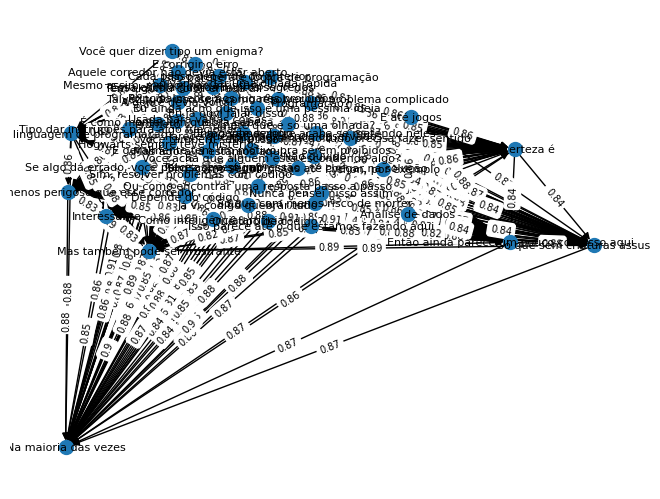

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences_e5):
    G.add_node(i, label=s)

for i in range(n):
    for j in range(n):
        weight = A[i, j]
        if weight > 0.2:
            G.add_edge(j, i, weight=weight)

pos = nx.spring_layout(G)

nx.draw(G, pos, node_size=100)

node_labels = {i: s for i, s in enumerate(sentences)}
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8)

edge_labels = {k: round(v, 2) for k, v in nx.get_edge_attributes(G, 'weight').items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()

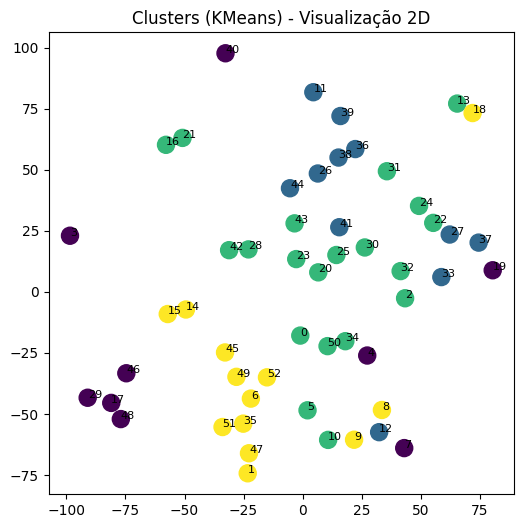

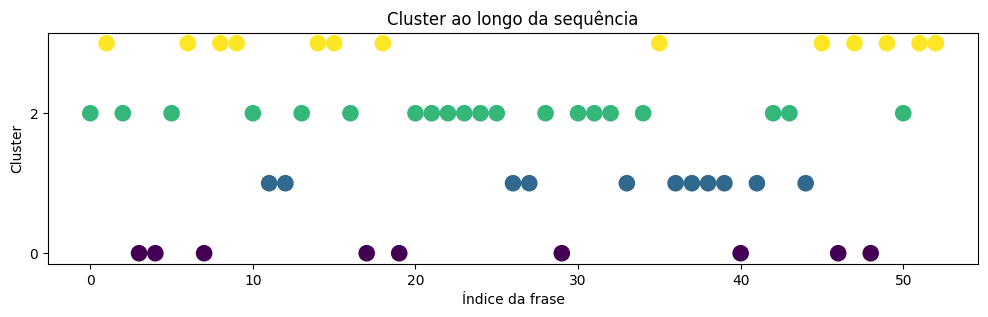

In [14]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

S_norm = normalize(S)

kmeans = KMeans(n_clusters=4, random_state=0)
labels = kmeans.fit_predict(S_norm)

tsne = TSNE(n_components=2, random_state=0, perplexity=5)
S_2d = tsne.fit_transform(S_norm)


plt.figure(figsize=(6,6))
plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=150)

for i in range(len(sentences)):
    plt.text(S_2d[i,0], S_2d[i,1], str(i), fontsize=8)

plt.title("Clusters (KMeans) - Visualização 2D")
plt.show()

plt.figure(figsize=(12,3))
plt.scatter(range(len(sentences)), labels, c=labels, s=120)

plt.yticks([0,2])
plt.xlabel("Índice da frase")
plt.ylabel("Cluster")
plt.title("Cluster ao longo da sequência")

plt.show()

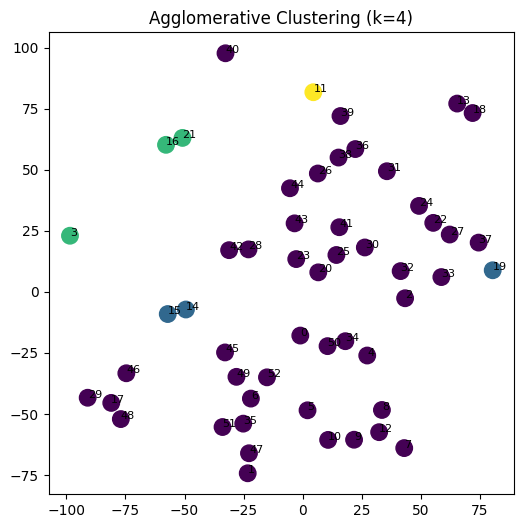

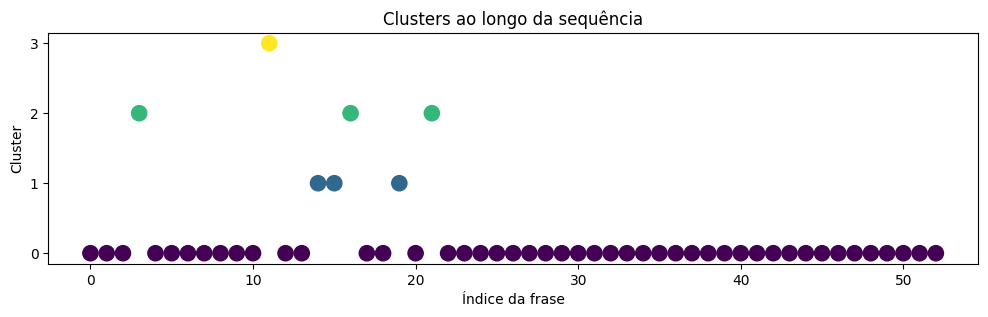

In [ ]:
from sklearn.cluster import AgglomerativeClustering

S_norm = normalize(S)

k = 4
clustering = AgglomerativeClustering(
    n_clusters=k,
    metric='cosine',
    linkage='average'
)

labels = clustering.fit_predict(S_norm)

tsne = TSNE(n_components=2, random_state=0, perplexity=5)
S_2d = tsne.fit_transform(S_norm)

plt.figure(figsize=(6,6))
plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=140)

for i in range(len(sentences)):
    plt.text(S_2d[i,0], S_2d[i,1], str(i), fontsize=8)

plt.title(f"Agglomerative Clustering (k={k})")
plt.show()

plt.figure(figsize=(12,3))
plt.scatter(range(len(sentences)), labels, c=labels, s=120)

plt.yticks(range(k))
plt.xlabel("Índice da frase")
plt.ylabel("Cluster")
plt.title("Clusters ao longo da sequência")

plt.show()

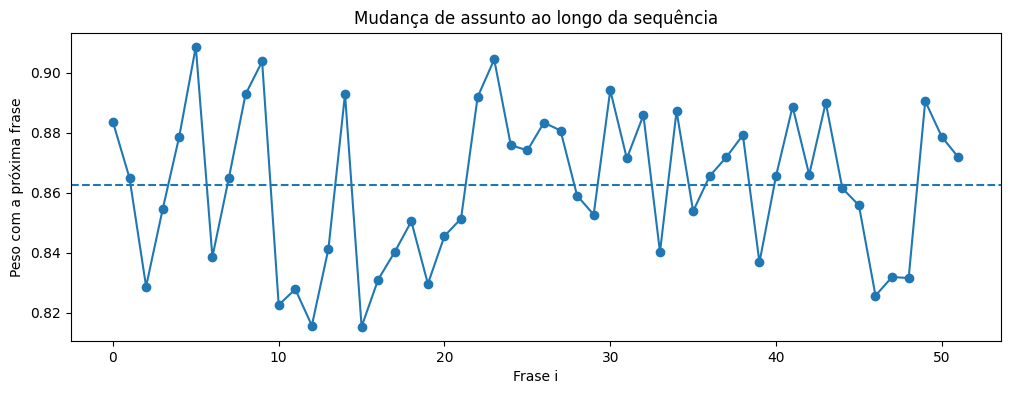

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

S_norm = normalize(S)

weights = np.array([
    cosine_similarity(S_norm[i].reshape(1, -1), S_norm[i+1].reshape(1, -1))[0, 0]
    for i in range(len(S_norm) - 1)
])


plt.figure(figsize=(12, 4))
plt.plot(weights, marker='o')
plt.axhline(np.mean(weights), linestyle='--')
plt.xlabel("Frase i")
plt.ylabel("Peso com a próxima frase")
plt.title("Mudança de assunto ao longo da sequência")
plt.show()

In [5]:
def cosine(a, b):
    return cosine_similarity(a.reshape(1, -1), b.reshape(1, -1))[0, 0]

k = 3  

pivot_scores = []

for i in range(k, len(S_norm) - k):
    prev_ctx = S_norm[i-k:i].mean(axis=0)
    next_ctx = S_norm[i+1:i+k+1].mean(axis=0)
    score = 1 - cosine(prev_ctx, next_ctx)
    pivot_scores.append((i, score))

pivot_scores.sort(key=lambda x: x[1], reverse=True)

print("Frases mais relevantes para mudança de rumo:")
for i, score in pivot_scores[:5]:
    print(f"\nÍndice {i} | score = {score:.4f}")
    print(sentences[i])

Frases mais relevantes para mudança de rumo:

Índice 12 | score = 0.0911
Então vamos logo

Índice 13 | score = 0.0789
Essa escola guarda muitos segredos

Índice 20 | score = 0.0710
Talvez tudo isso seja como resolver um problema complicado

Índice 35 | score = 0.0705
Só que com menos risco de morrer

Índice 36 | score = 0.0697
Depende do código
